# **Exercício 6**

 **Discente:** Raphael Ramos da Silva

Realizar o exercício de sparse coding no link http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.Sparse/Chapter.Sparse2/lab.html

- Entregar em Python notebook ou Matlab, com comentários sobre a atividade

**1. Play with the parameters: a) the size and the number of the filter in the training phase, b) the coefficient of l1 norm $\beta$ in the denoising phase to see how the denoising results are going to change.**

O parâmetro `filter_size` é uma lista que contém a especificação do tamanho dos filtros utilizados na fase de treino.

Valor padrão: `filter_size = [21, 11, 3]` (3 filtros de tamanho 21x11)

**NOTE:** Obrigatoriamente, cada dimensão do filtro deve ser ímpar, porque o solver calcula o centro do filtro.


In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def mostrar(caminhos, titulos, ncols=2, largura=14, altura=5):
    """Plota imagens salvas pelos scripts MATLAB lado a lado."""
    nrows = -(-len(caminhos) // ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(largura, altura * nrows))
    for ax in fig.axes:
        ax.axis('off')
    for ax, c, t in zip(fig.axes, caminhos, titulos):
        ax.imshow(mpimg.imread(c))
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

Q1 = 'imagens/q1/'
Q2 = 'imagens/q2/'

### a) Tamanho e número de filtros (β = 1)

O dado ruidoso tem SNR = 7,18 dB em todos os casos.

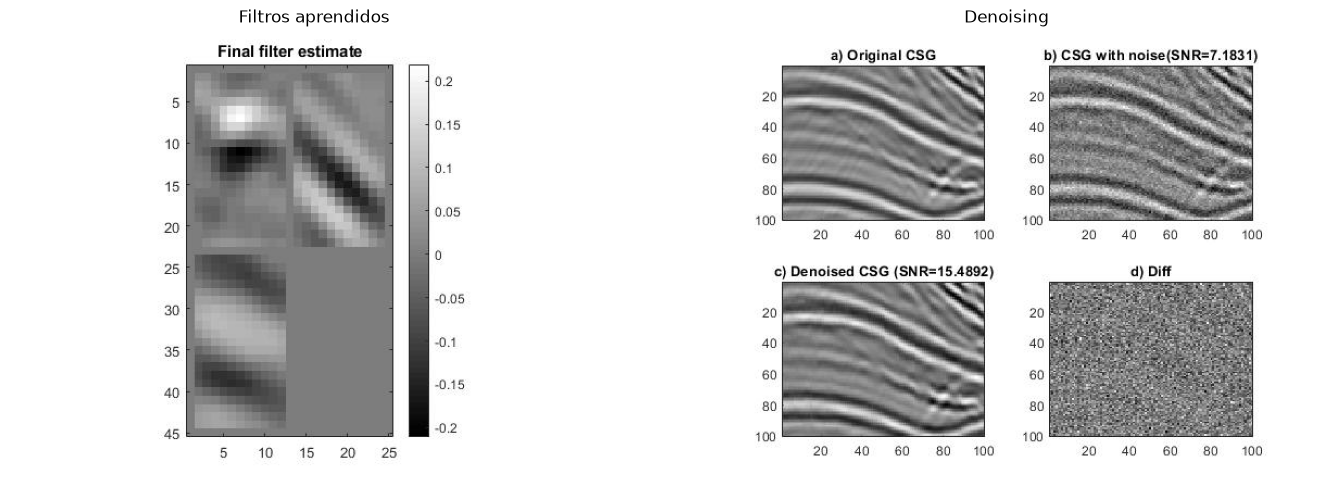

In [3]:
# [21, 11, 3] beta = 1.0 (original)
mostrar([Q1 + 'training_phase_21_11_3.jpg', Q1 + 'denoising_21_11_3.jpg'],
        ['Filtros aprendidos', 'Denoising'])

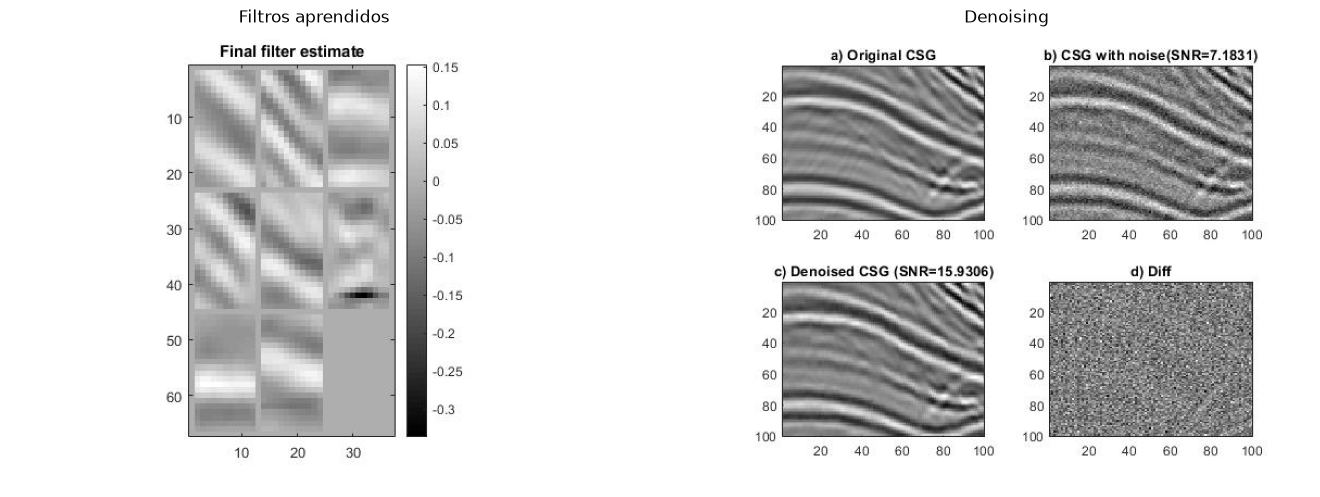

In [4]:
# [21, 11, 8] beta = 1.0
mostrar([Q1 + 'training_phase_21_11_8.jpg', Q1 + 'denoising_21_11_8.jpg'],
        ['Filtros aprendidos', 'Denoising'])

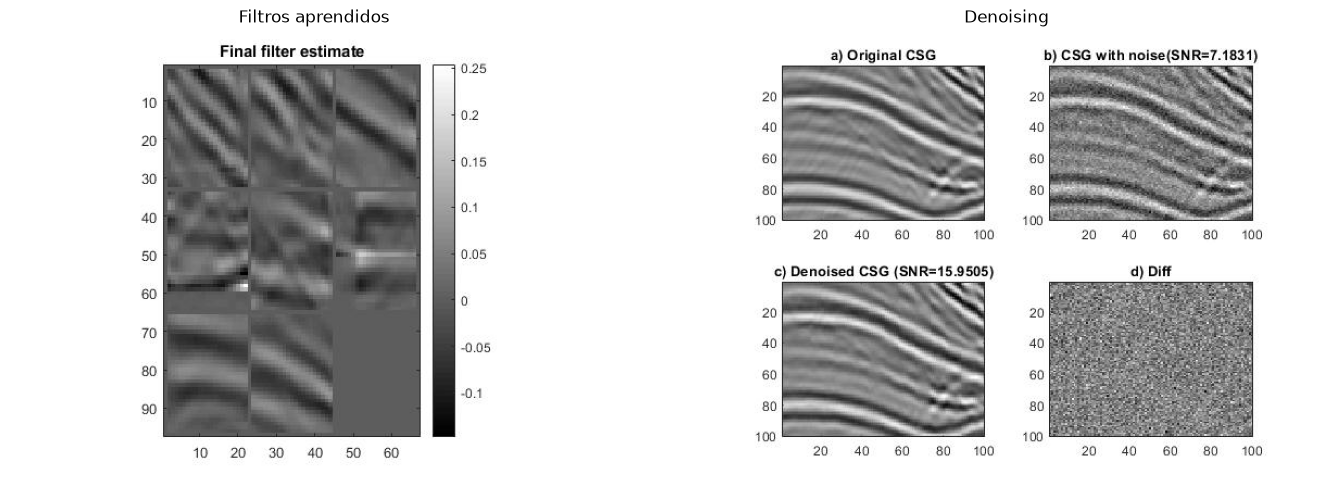

In [5]:
# [31, 21, 8] beta = 1.0
mostrar([Q1 + 'training_phase_31_21_8.jpg', Q1 + 'denoising_31_21_8.jpg'],
        ['Filtros aprendidos', 'Denoising'])

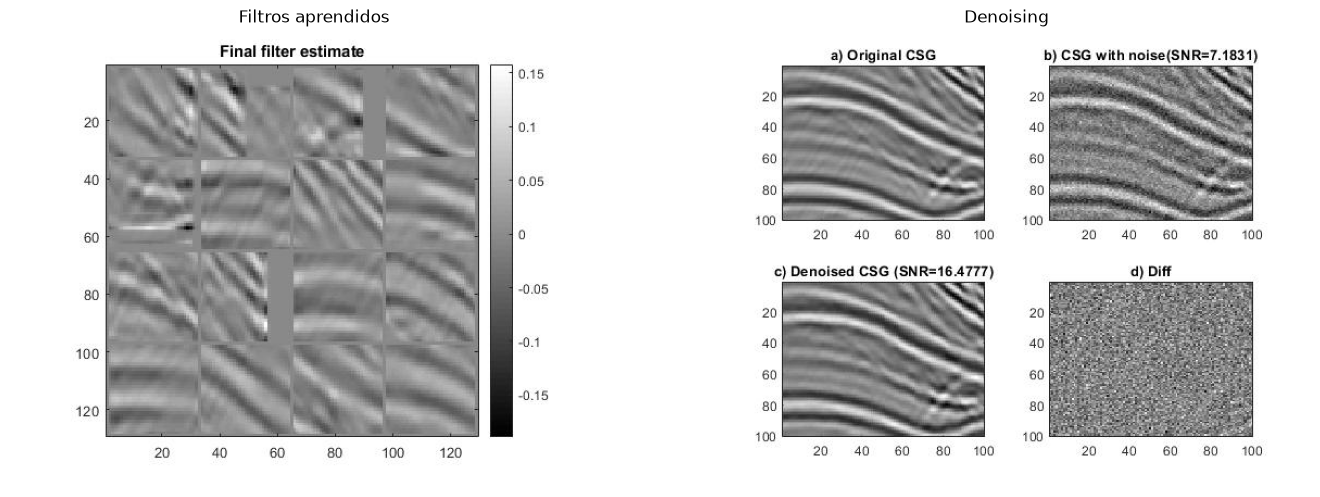

In [6]:
# [31, 31, 16] beta = 1.0
mostrar([Q1 + 'training_phase_31_31_16.jpg', Q1 + 'denoising_31_31_16.jpg'],
        ['Filtros aprendidos', 'Denoising'])

Resultados:

- [21, 11, 3]: SNR = 15,49 dB. Três filtros que capturam a orientação dominante dos eventos (um horizontal e dois inclinados).
- [21, 11, 8]: SNR = 15,93 dB. Com mais filtros surgem outras inclinações e alguns filtros mais localizados, que representam bordas e o cruzamento de eventos perto de (80, 80).
- [31, 21, 8]: SNR = 15,95 dB. Filtros maiores capturam trechos mais longos e curvos dos eventos, com ganho marginal em relação ao caso anterior.
- [31, 31, 16]: SNR = 16,48 dB (melhor). Dicionário mais rico, com várias inclinações e curvaturas, mas o treino é mais caro e alguns filtros ficam redundantes ou com aspecto de ruído.

Aumentar o número e o tamanho dos filtros melhora o denoising, porque o dicionário representa melhor a variedade de estruturas do dado, mas o ganho é decrescente e o custo computacional cresce.

### b) Coeficiente β da norma ℓ1 (filtros [21, 11, 3])

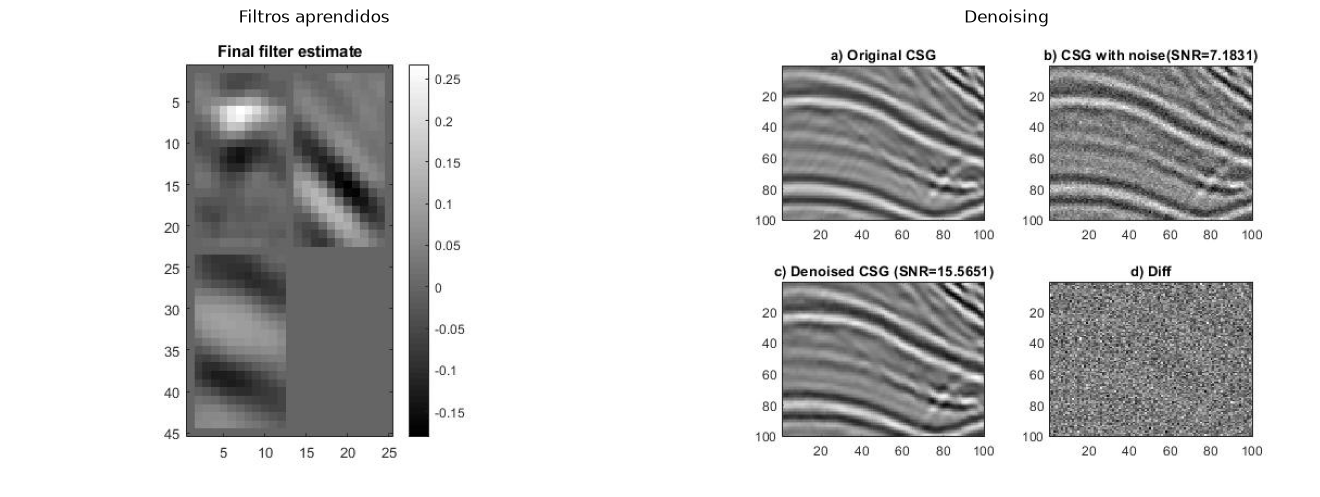

In [7]:
# [21, 11, 3] beta = 0.5
mostrar([Q1 + 'training_phase_21_11_3_beta0_5.jpg', Q1 + 'denoising_21_11_3_beta0_5.jpg'],
        ['Filtros aprendidos', 'Denoising'])

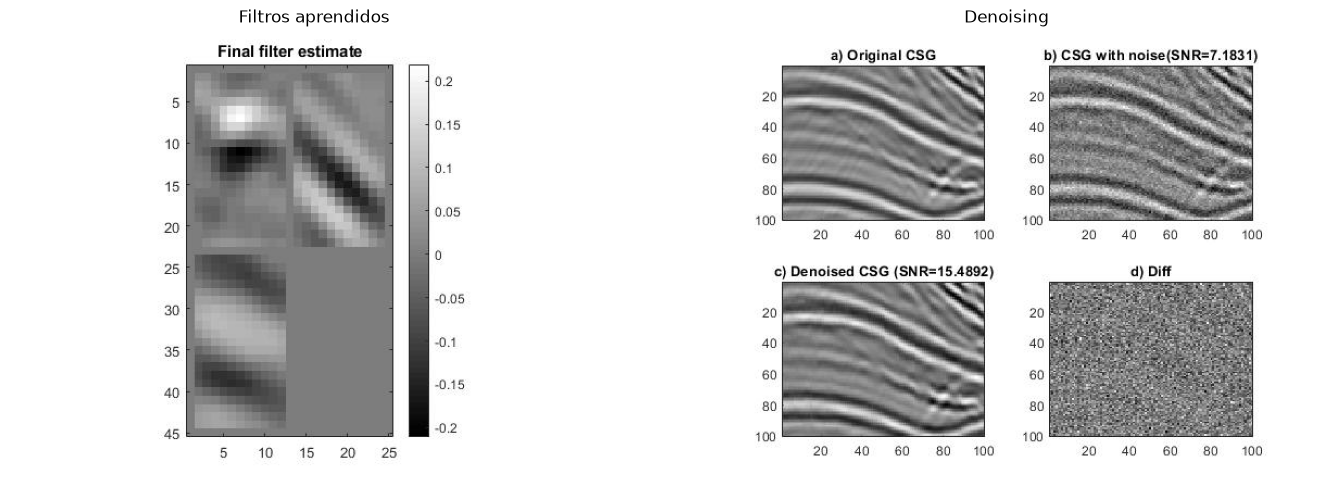

In [8]:
# [21, 11, 3] beta = 1.0
mostrar([Q1 + 'training_phase_21_11_3.jpg', Q1 + 'denoising_21_11_3.jpg'],
        ['Filtros aprendidos', 'Denoising'])

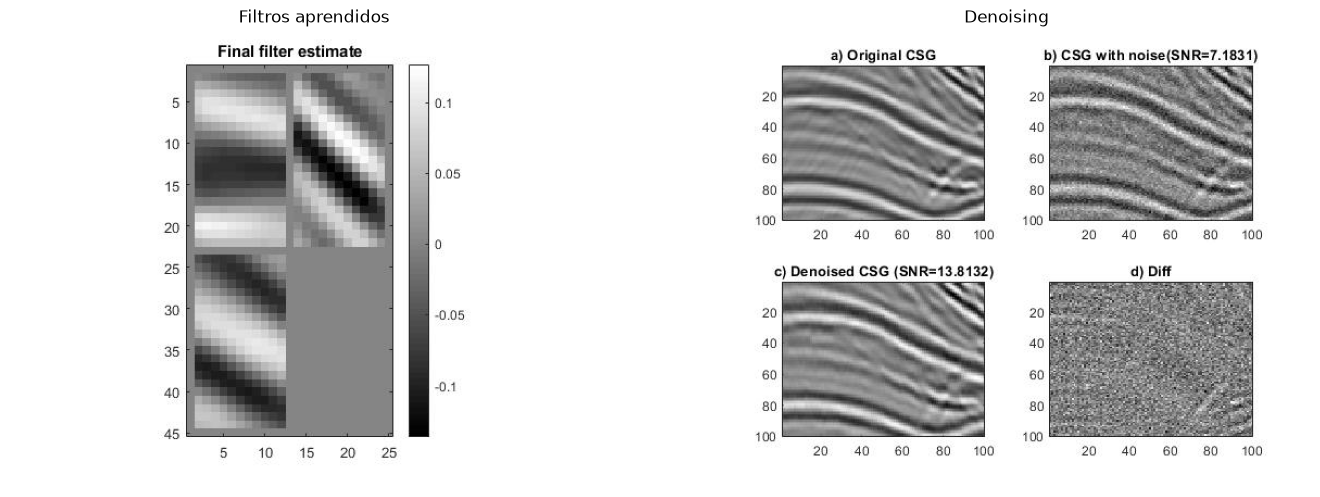

In [9]:
# [21, 11, 3] beta = 5.0
mostrar([Q1 + 'training_phase_21_11_3_beta_5.jpg', Q1 + 'denoising_21_11_3_beta_5.jpg'],
        ['Filtros aprendidos', 'Denoising'])

Resultados:

- β = 0,5: SNR = 15,57 dB. Representação menos esparsa; filtros menos suaves e mais localizados.
- β = 1,0: SNR = 15,49 dB.
- β = 5,0: SNR = 13,81 dB. Os filtros ficam suaves e bem orientados, mas a penalização forte zera coeficientes demais e o sinal é suavizado em excesso. Na diferença aparecem resquícios dos eventos (principalmente no cruzamento perto de (80, 80)), indicando perda de sinal.

β controla o compromisso entre fidelidade aos dados e esparsidade: valores baixos preservam mais o sinal, valores altos removem ruído junto com parte do sinal. Para este dado, β entre 0,5 e 1 deu os melhores resultados.

**2. Compare the filters of CSC to those of the first layer of CNN. What's the similarity and difference between them?**

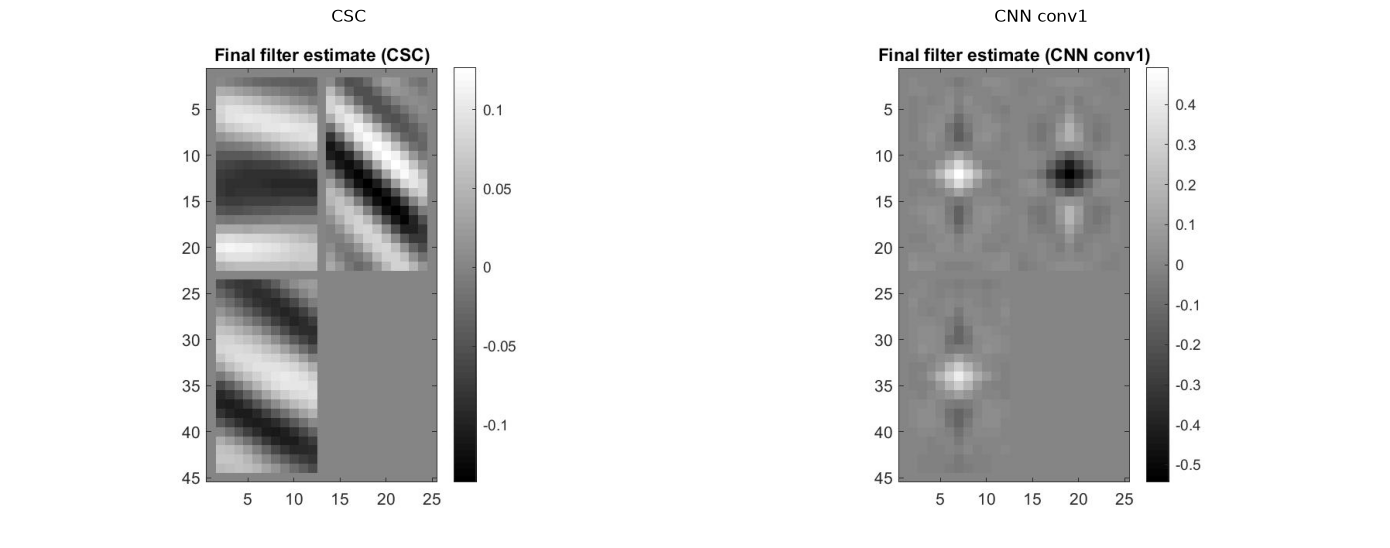

In [10]:
# Filtros do CSC (filters.mat) x filtros da 1a camada de uma CNN rasa
# treinada no mesmo dado (ruidoso -> limpo), com 3 filtros 21x11 (training_phase_conv.m)
mostrar([Q2 + 'filtros_csc.jpg', Q2 + 'filtros_cnn_conv1.jpg'],
        ['CSC', 'CNN conv1'], altura=7)

Para a comparação foi treinada uma CNN rasa (conv 21x11 com 3 filtros, ReLU, conv 1x1) no mesmo sismograma, com o mesmo número e tamanho de filtros do CSC, de forma supervisionada (dado ruidoso → dado limpo).

Semelhanças:

- Ambos são bancos de filtros convolucionais aprendidos a partir dos dados, sem projeto manual, que funcionam como detectores de padrões locais.
- Os dois se adaptam ao conteúdo de frequência do sismograma.

Diferenças:

- Forma: os filtros do CSC são átomos que se parecem com pedaços dos eventos sísmicos (ondulações orientadas que seguem a inclinação dos refletores). Os da CNN são compactos e quase isotrópicos, com um pico central (positivo ou negativo) e pequenos lóbulos, parecidos com operadores passa-baixa ou laplaciano. A maior parte do suporte 21x11 fica perto de zero.
- Objetivo: o CSC é não supervisionado e aprende filtros que reconstroem o sinal com poucos coeficientes. A CNN aprende filtros que minimizam o erro de saída, e por isso converge para operadores de suavização em vez de átomos que representam o sinal.
- Restrições: no CSC cada filtro tem norma ℓ2 ≤ 1 e a esparsidade é imposta pelo termo ℓ1 nos mapas z. Na CNN não há restrição de norma (pesos até ±0,5, contra ±0,13 no CSC) e a esparsidade é apenas implícita, via ReLU.
- Inferência: no CSC, obter os coeficientes exige resolver um problema de otimização (ADMM). Na CNN, basta uma convolução seguida de uma não linearidade.

**NOTE:** os filtros CSC acima vêm do `filters.mat` atual, gerado com β = 5.